### 1. Cargar los datos


In [8]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/parkinsons_updrs.data'
df = pd.read_csv(file_path)
print(df.head())
# Número total de pacientes (filas en el DataFrame)
print(f"Número total de pacientes: {len(df)}")
print(f"Número total de pacientes: {df.shape[0]}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   subject#  age  sex  test_time  motor_UPDRS  total_UPDRS  Jitter(%)  \
0         1   72    0     5.6431       28.199       34.398    0.00662   
1         1   72    0    12.6660       28.447       34.894    0.00300   
2         1   72    0    19.6810       28.695       35.389    0.00481   
3         1   72    0    25.6470       28.905       35.810    0.00528   
4         1   72    0    33.6420       29.187       36.375    0.00335   

   Jitter(Abs)  Jitter:RAP  Jitter:PPQ5  ...  Shimmer(dB)  Shimmer:APQ3  \
0     0.000034     0.00401      0.00317  ...        0.230       0.01438   
1     0.000017     0.00132      0.00150  ...        0.179       0.00994   
2     0.000025     0.00205      0.00208  ...        0.181       0.00734   
3     0.000027     0.00191      0.00264  ...        0.327       0.01106   
4     0.000020     0.00093      0.00130  ...        0.176

### 2. Realizar un estadística descriptiva univariante de las variables que incluya tablas y gráficos.
Para este apartado, realizaremos primero un análisis de las principales características estadisticas del dataset (media, varianza, curtosis etc.), después realizaremos tanto un histograma para observar la normalidad de los datos como un boxplot para la detección de outliers.

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
# Crear tabla resumen profesional
descripcion = df.describe().T
descripcion['variance'] = df.var()
descripcion['mode'] = df.mode().iloc[0]
descripcion['skewness'] = df.skew()
descripcion['kurtosis'] = df.kurtosis()

print("ESTADÍSTICAS DESCRIPTIVAS COMPLETAS")
print("="*50)
print(descripcion.round(3))

ESTADÍSTICAS DESCRIPTIVAS COMPLETAS
                count    mean     std     min     25%     50%      75%  \
subject#       5875.0  21.494  12.372   1.000  10.000  22.000   33.000   
age            5875.0  64.805   8.822  36.000  58.000  65.000   72.000   
sex            5875.0   0.318   0.466   0.000   0.000   0.000    1.000   
test_time      5875.0  92.864  53.446  -4.262  46.848  91.523  138.445   
motor_UPDRS    5875.0  21.296   8.129   5.038  15.000  20.871   27.596   
total_UPDRS    5875.0  29.019  10.700   7.000  21.371  27.576   36.399   
Jitter(%)      5875.0   0.006   0.006   0.001   0.004   0.005    0.007   
Jitter(Abs)    5875.0   0.000   0.000   0.000   0.000   0.000    0.000   
Jitter:RAP     5875.0   0.003   0.003   0.000   0.002   0.002    0.003   
Jitter:PPQ5    5875.0   0.003   0.004   0.000   0.002   0.002    0.003   
Jitter:DDP     5875.0   0.009   0.009   0.001   0.005   0.007    0.010   
Shimmer        5875.0   0.034   0.026   0.003   0.019   0.028    0.040   
Sh

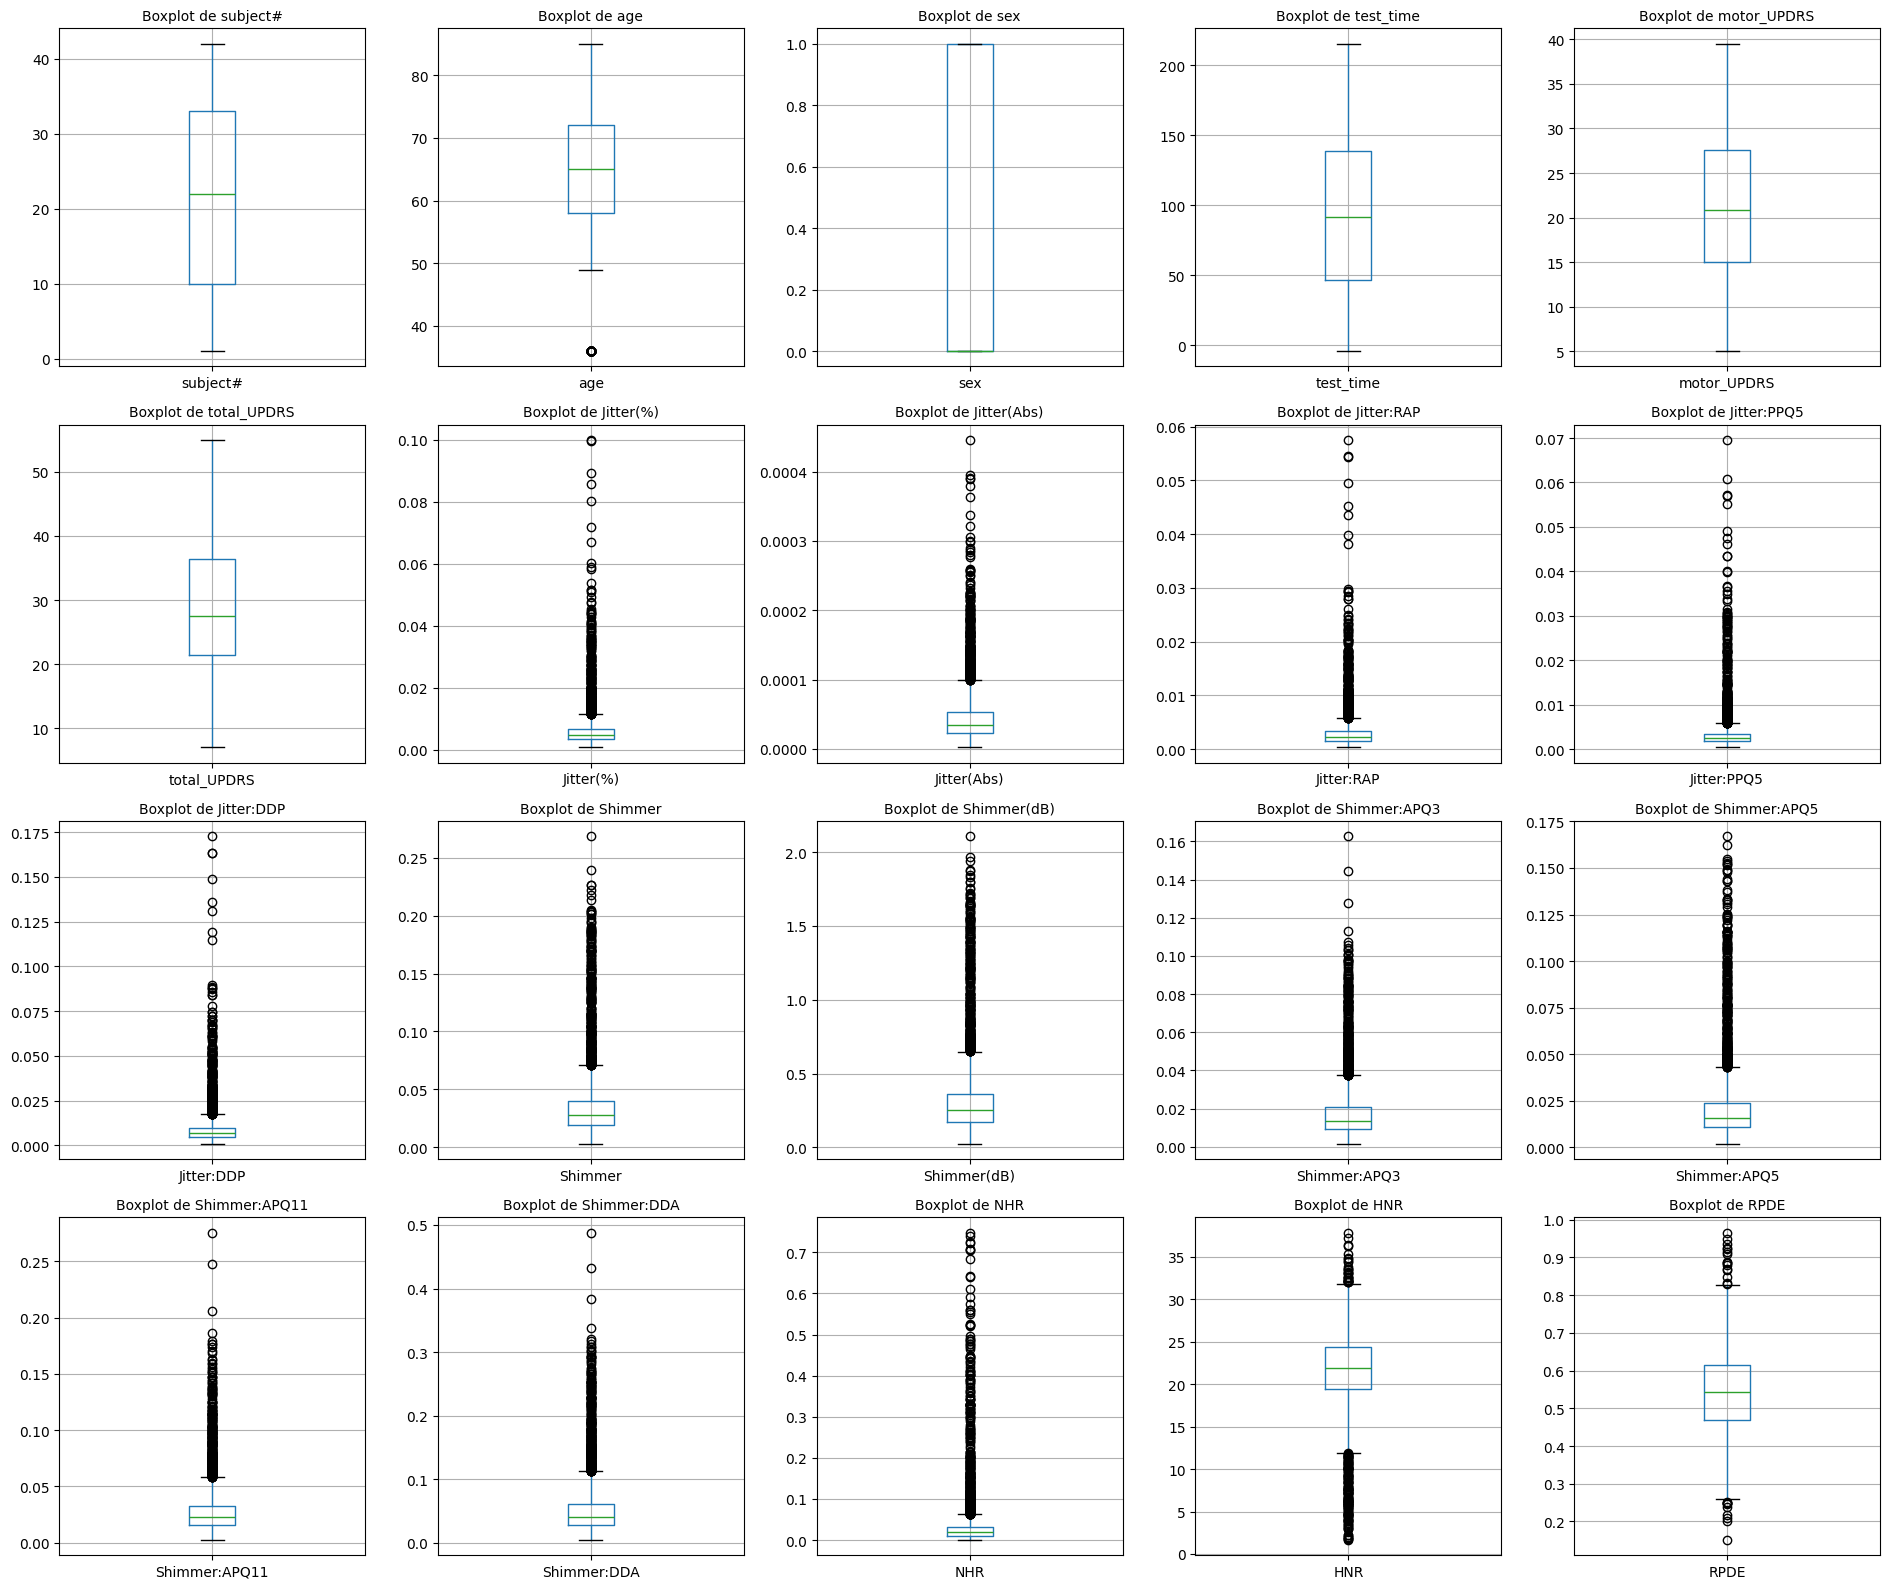

In [10]:
fig, axes = plt.subplots(4, 5, figsize=(19, 16))
axes = axes.ravel()
numeric_columns = df.select_dtypes(include=[np.number]).columns
for i, col in enumerate(numeric_columns[:20]):
    df.boxplot(column=col, ax=axes[i])
    axes[i].set_title(f'Boxplot de {col}', fontsize=10)

plt.tight_layout()
plt.show()

### 3. Estandarizar mediante la transformación min-max las 16 variables que representan medidas biomédicas de la voz. Mostrar graficamente la transformación de las variables.

In [11]:
# Las 16 variables biomédicas de voz exactas
variables_voz = [
    'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP',
    'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11',
    'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE'
]
from sklearn.preprocessing import MinMaxScaler

# Seleccionar solo las variables de voz
df_voz = df[variables_voz].copy()

# Aplicar transformación Min-Max
scaler = MinMaxScaler()
df_voz_escalado = pd.DataFrame(
    scaler.fit_transform(df_voz),
    columns=[f"{col}_scaled" for col in variables_voz],
    index=df.index
)

# Combinar datos originales y escalados para comparación
df_comparacion = pd.concat([df_voz, df_voz_escalado], axis=1)

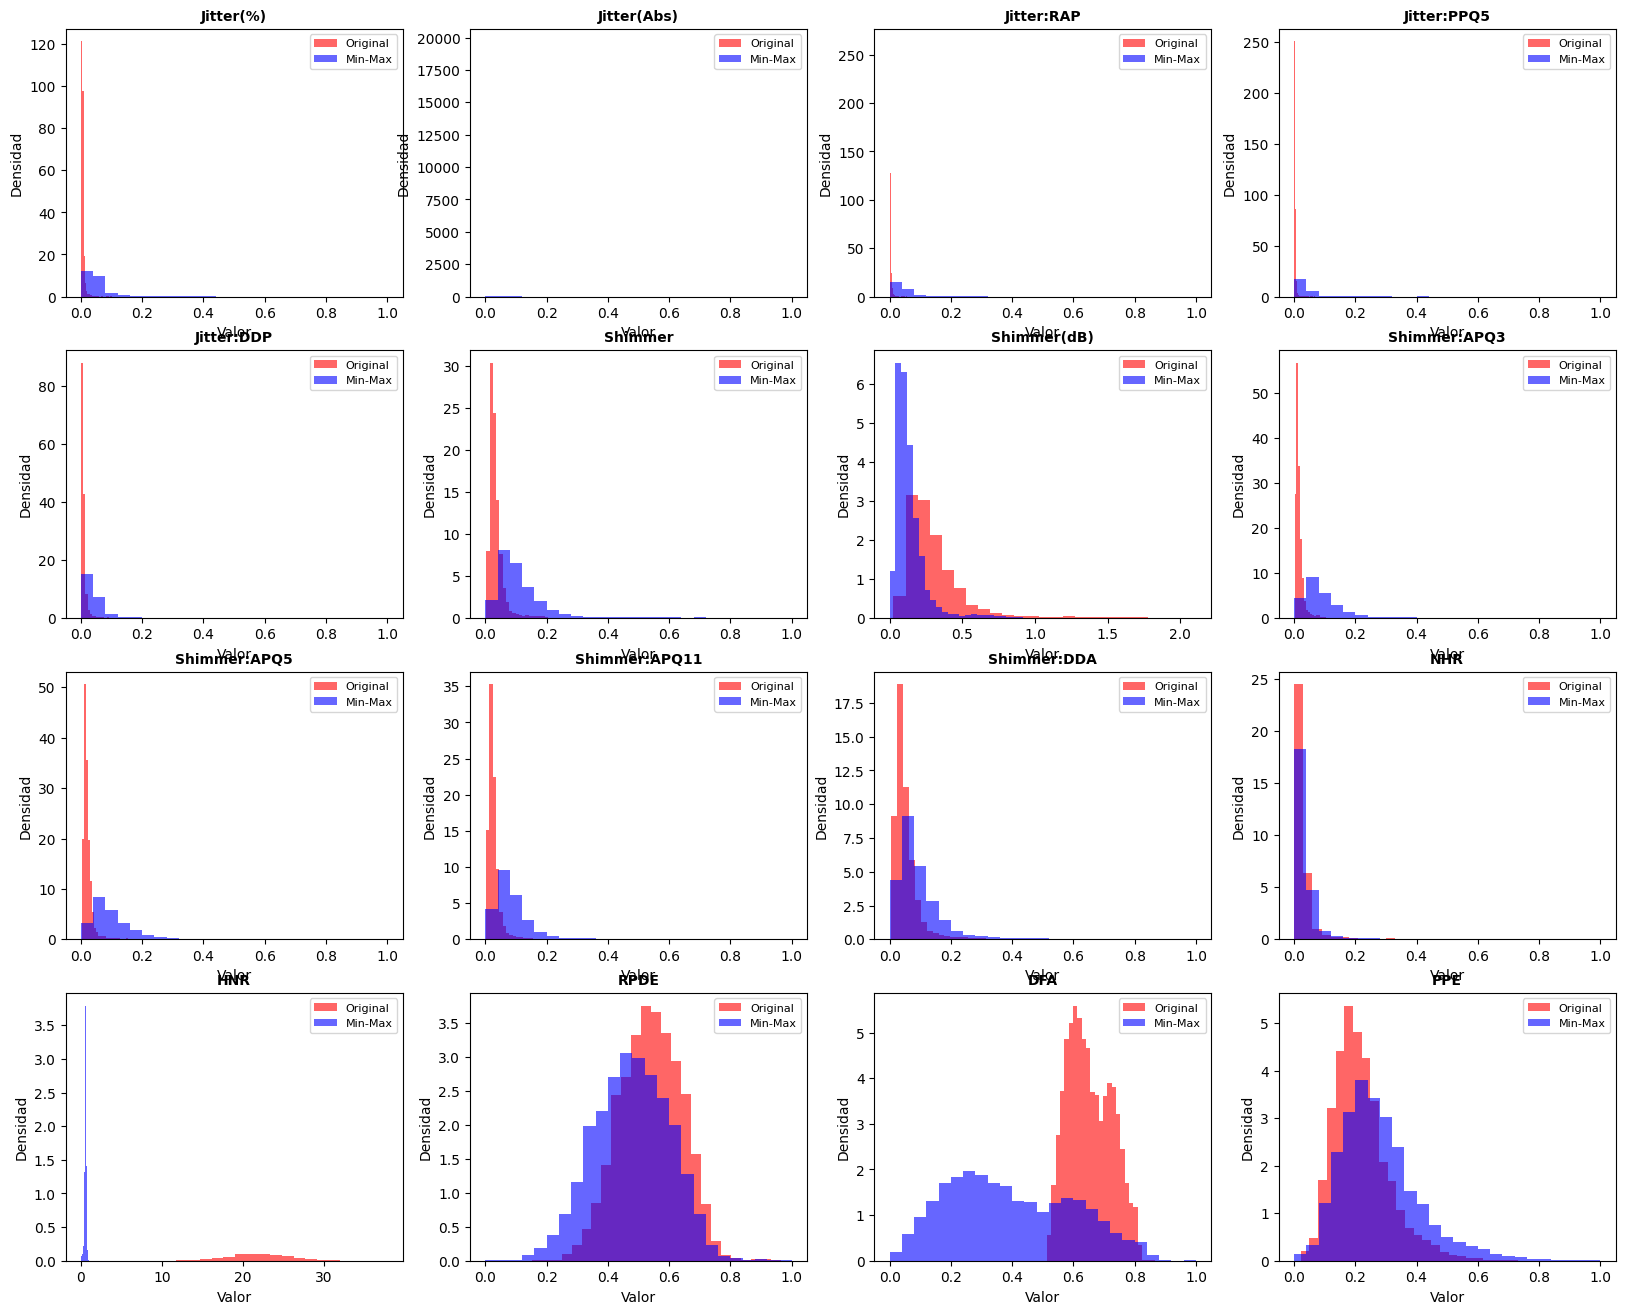

In [12]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.ravel()

for i, col in enumerate(variables_voz):
    # Datos originales (rojo)
    axes[i].hist(df_voz[col], bins=25, alpha=0.6, color='red', label='Original', density=True)
    # Datos escalados (azul)
    axes[i].hist(df_voz_escalado[f"{col}_scaled"], bins=25, alpha=0.6, color='blue', label='Min-Max', density=True)

    axes[i].set_title(f'{col}', fontsize=10, fontweight='bold')
    axes[i].legend(fontsize=8)
    axes[i].set_xlabel('Valor')
    axes[i].set_ylabel('Densidad')


### 4. Crear la variable binaria de severidad del Parkinson. Mostrar en una tabla el numero de observaciones por severidad del Parkinson.
Para la creación de esta variable utilizaremos lavariable total_UPDRS ya que esta se realciona directamnete con la vida del paciente, mientras que la variable motor_UPDRS solo se relaciona con la función motora del individuo a estudio.

In [17]:
# Usando total_UPDRS con umbral clínico estándar
if 'total_UPDRS' in df.columns:
    # Consideramos los umbrales clínicos comunes donde leve se da cuando total_UPDRS < 25
    #  y moderado-severo se da cuando total_UPDRS >= 25
    df['severidad_parkinson'] = np.where(df['total_UPDRS'] >= 25,
    'Moderado-Severo', 'Leve')
    print("Variable de severidad creada basada en total_UPDRS")

Variable de severidad creada basada en total_UPDRS


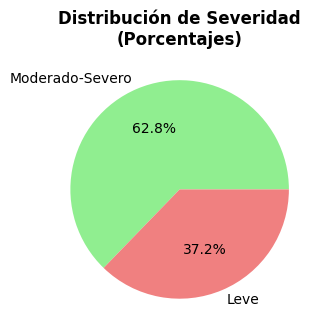

In [18]:
# Gráfico: Pie chart de porcentajes
plt.subplot(1, 2, 2)
df['severidad_parkinson'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                          colors=['lightgreen', 'lightcoral'])
plt.title('Distribución de Severidad\n(Porcentajes)', fontweight='bold')
plt.ylabel('')

plt.tight_layout()
plt.show()

### 5. Implementar una divisón del dataset 67% train y 33% test

In [9]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['severidad_parkinson'])
y = df['severidad_parkinson']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, train_size=0.67,random_state=42)

6. ### Implementar una red neuronal profunda densa para la predicción de la severidad con dos capas ocultas de 10 y 10 nodos cada una. Adicionalmente, implementar una segunda red neuronal profunda densa con tres capas ocultas de 10, 20 y 10 nodos cada una.
En este ejercicio estableceremos dos modelos de redes neuronales.
Uno simple con dos capas ocultas y 10 neuronas cada una. Y otro complejo
con 3 capas ocultas y 10, 20 y 10 neuronas respectivamente

In [10]:
from tensorflow.keras.models import Sequential
from keras.layers import Dense, Activation
from keras.optimizers import SGD, Adam

# Utilizaremos el modelo secuencial, debido a que es el más utlizado en redes neuronales
model = Sequential()
#
model.add(Dense(10, activation='relu', input_shape=(X_train.shape[1],), kernel_initializer='he_uniform'))
model.add(Dense(10, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(1, activation='sigmoid', kernel_initializer='glorot_uniform'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf

# Convertir las etiquetas de texto a números
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)
model.compile(SGD(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

In [12]:
history = model.fit(X_train, y_train_encoded, validation_data=(X_test, y_test_encoded), epochs=100, verbose=2)

Epoch 1/100
123/123 - 1s - 10ms/step - accuracy: 0.7785 - loss: 0.7862 - val_accuracy: 0.9103 - val_loss: 0.2111
Epoch 2/100
123/123 - 0s - 3ms/step - accuracy: 0.8831 - loss: 0.2776 - val_accuracy: 0.9278 - val_loss: 0.1807
Epoch 3/100
123/123 - 0s - 3ms/step - accuracy: 0.9052 - loss: 0.2291 - val_accuracy: 0.9371 - val_loss: 0.1698
Epoch 4/100
123/123 - 0s - 3ms/step - accuracy: 0.9217 - loss: 0.2016 - val_accuracy: 0.9304 - val_loss: 0.1704
Epoch 5/100
123/123 - 0s - 3ms/step - accuracy: 0.9141 - loss: 0.2075 - val_accuracy: 0.8938 - val_loss: 0.2158
Epoch 6/100
123/123 - 0s - 3ms/step - accuracy: 0.9238 - loss: 0.1865 - val_accuracy: 0.9252 - val_loss: 0.1708
Epoch 7/100
123/123 - 0s - 3ms/step - accuracy: 0.9296 - loss: 0.1770 - val_accuracy: 0.9500 - val_loss: 0.1493
Epoch 8/100
123/123 - 0s - 3ms/step - accuracy: 0.9365 - loss: 0.1664 - val_accuracy: 0.9335 - val_loss: 0.1728
Epoch 9/100
123/123 - 0s - 3ms/step - accuracy: 0.9322 - loss: 0.1697 - val_accuracy: 0.9242 - val_loss

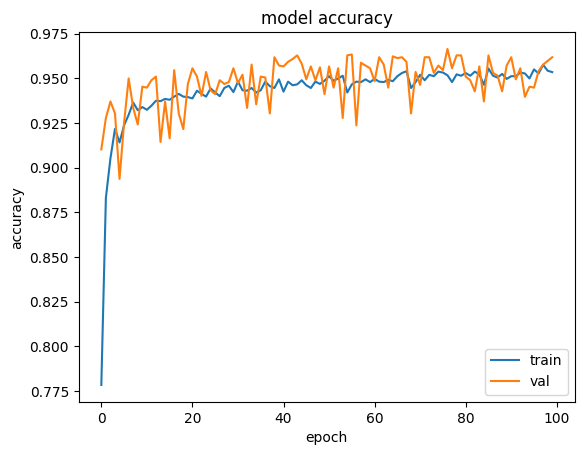

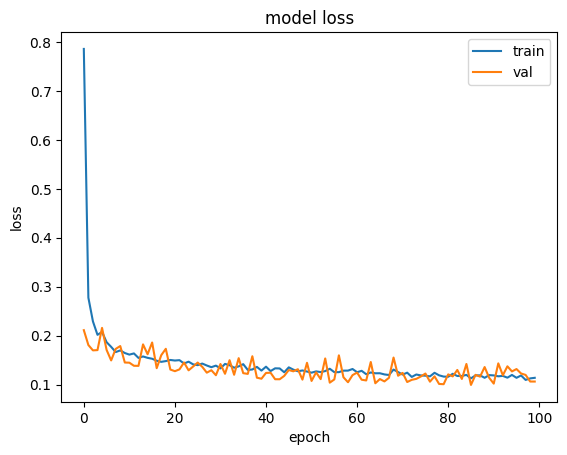

In [13]:
# Visualización del accuracy del modelo simple
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='lower right')
plt.show()

# Visualización del loss del modelo simple.
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.show()

Ahora vamos a por la red neuronal de tres capas con 10, 20 y 10 neuronas respectivamente

In [15]:
model2 = Sequential()
model2.add(Dense(10, activation='relu', input_shape=(X_train.shape[1],), kernel_initializer='he_uniform'))
model2.add(Dense(20, activation='relu', kernel_initializer='he_uniform'))
model2.add(Dense(10, activation='relu', kernel_initializer='he_uniform'))
model2.add(Dense(1, activation='sigmoid', kernel_initializer='glorot_uniform'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
from keras.optimizers import SGD
model2.compile(SGD(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

In [17]:
history2 = model2.fit(X_train, y_train_encoded, validation_data=(X_test, y_test_encoded), epochs=25, verbose=2)

Epoch 1/25
123/123 - 1s - 12ms/step - accuracy: 0.7736 - loss: 0.6460 - val_accuracy: 0.8597 - val_loss: 0.3627
Epoch 2/25
123/123 - 0s - 4ms/step - accuracy: 0.8686 - loss: 0.3709 - val_accuracy: 0.9103 - val_loss: 0.2213
Epoch 3/25
123/123 - 1s - 5ms/step - accuracy: 0.8968 - loss: 0.2511 - val_accuracy: 0.7942 - val_loss: 0.4819
Epoch 4/25
123/123 - 1s - 4ms/step - accuracy: 0.9037 - loss: 0.2221 - val_accuracy: 0.9257 - val_loss: 0.1974
Epoch 5/25
123/123 - 1s - 5ms/step - accuracy: 0.9101 - loss: 0.2200 - val_accuracy: 0.9242 - val_loss: 0.1913
Epoch 6/25
123/123 - 0s - 3ms/step - accuracy: 0.9096 - loss: 0.2065 - val_accuracy: 0.9020 - val_loss: 0.2579
Epoch 7/25
123/123 - 0s - 3ms/step - accuracy: 0.9146 - loss: 0.1948 - val_accuracy: 0.9273 - val_loss: 0.1830
Epoch 8/25
123/123 - 0s - 3ms/step - accuracy: 0.9118 - loss: 0.2058 - val_accuracy: 0.8948 - val_loss: 0.2557
Epoch 9/25
123/123 - 0s - 3ms/step - accuracy: 0.9182 - loss: 0.1863 - val_accuracy: 0.9257 - val_loss: 0.1805


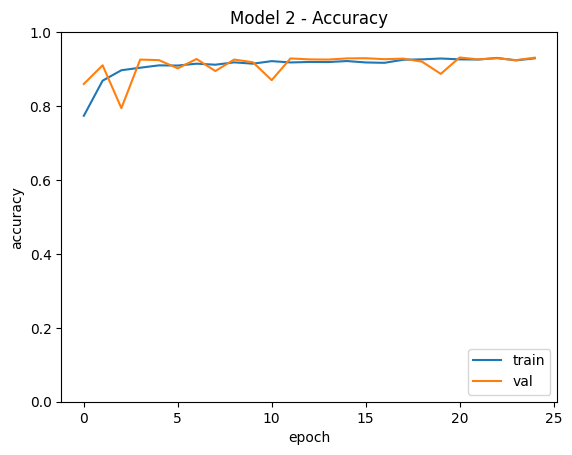

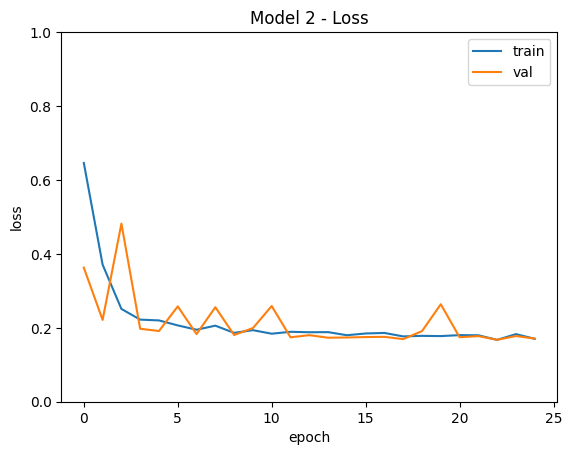

In [18]:
# Visualizar accuracy del modelo complejo
plt.plot(history2.history['accuracy'])
plt.plot(history2.history['val_accuracy'])
plt.title('Model 2 - Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='lower right')
plt.ylim(0, 1)  # Límite del eje Y de 0 a 1
plt.show()

# Visualizar loss del modelo complejo
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])
plt.title('Model 2 - Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.ylim(0, 1)  # Límite del eje Y de 0 a 1
plt.show()

### Comparar el rendimiento de las dos redes neuronales en el conjunto test mediante sus curvas ROC y al menos otras 4 medidas de metricas de calidad. Crear tabla resumen.

In [24]:
from sklearn.metrics import (roc_curve, auc, confusion_matrix, classification_report,  precision_score, recall_score, f1_score, accuracy_score)
# Función para evaluar el modelo y generar métricas
def evaluate_model(model, X_test, y_test, model_name):
    # Predicciones
    y_pred_proba = model.predict(X_test).flatten()
    y_pred = (y_pred_proba > 0.5).astype(int)
    # Cálculo de métricas
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    # Curva ROC
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    return {
        'model_name': model_name,
        'y_test': y_test,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'fpr': fpr,
        'tpr': tpr,
        'roc_auc': roc_auc
    }
# Evaluar ambos modelos
results_model1 = evaluate_model(model, X_test, y_test_encoded, 'Modelo Simple')
results_model2 = evaluate_model(model2, X_test, y_test_encoded, 'Modelo Complejo')
# Crear tabla resumen de métricas
metrics_summary = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F measure', 'AUC'],
    'Modelo simple': [
        results_model1['accuracy'],
        results_model1['precision'],
        results_model1['recall'],
        results_model1['f1'],
        results_model1['roc_auc']
    ],
    'Modelo complejo': [
        results_model2['accuracy'],
        results_model2['precision'],
        results_model2['recall'],
        results_model2['f1'],
        results_model2['roc_auc']
    ]
})
print("=== TABLA RESUMEN DE MÉTRICAS ===")
print(metrics_summary.round(4))

61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
=== TABLA RESUMEN DE MÉTRICAS ===
     Métrica  Modelo simple  Modelo complejo
0   Accuracy         0.9618           0.9309
1  Precision         0.9441           0.8721
2     Recall         0.9521           0.9507
3  F measure         0.9481           0.9097
4        AUC         0.9922           0.9824


Como se puede observar el modelo simple tiene mejores parámetros estadísticos que modlo complejo, si bien el modelo complejo también tiene buenos valores estadísticos y su coste computacional es excelente. Uno de estos principales indicadores es la curva ROC cuyo AUC en ambos modelos es excelente, al igual que el f1 score que en ambos casoss es también excelente. Por lo tanto si bien el modelo simple es un  poquito mejor que el complejo, con el modelo complejo tienes un mucho menor coste computacional. El único parámetro donde hay un poco más de alejamiento es es en el de precisión, que en el modelo simple toma un valor de 0.94 y en el modelo complejo lo toma de 0.87, pero al ser una diferencia pequeña y al ser el recall (tasa de autenticos positivos del total de positivos detectados), el F measure, AUC y accuracy tan similares, y al reducirse el coste computacional considerablemente (no es lo mismo hjacer 100 ciclos que 25) me quedaría con el modelo complejo, ya que si esto se aplicase en hospitales no se dispone de unos grandes equipos, y la reducción en el tiempo de computación ayudaría a procesar un mayor número de muestras de pacientes.


 ### 8. Ya para acabar y como reflexión final, ¿crees que este conjunto de datos tiene alguna limitación como muestra representativa de la población de personas con Parkinson?. Justificar la respuesta.
 Puede tener limitaciones en tanto que el parkinson es una nefermedad que afecta a milones de personas en todo el mundo tanto hombrs como mujeres y del un rango de edad muy amplio. Por lo que aunque el tramaño muestral del dataset sea muy grande, 5875, pueden que todos los pacientes o un gran número sean hombres o que un gran º de individuos sean de un rango de edad muy concreto.
